# Stage 2 — Cleaning & Duplication Forensics

**Notebook 2 of 6** · Governed by `DOCS/STRUCTURE.md` Stage 2

---

## What this notebook is for

Stage 1 left four open items. This notebook resolves all four and produces the analysis-ready
dataset. It is the highest-stakes notebook in the project, because two of its decisions
determine whether every number that follows is real:

| # | Open item from Stage 1 | Resolved in |
|---|---|---|
| 1 | 723 duplicate rows (70.5% of the file) | §2.1 — deduplication **forensics**, not just `drop_duplicates()` |
| 2 | `thal = 0`, outside the permitted set {1,2,3} | §2.2 — recode to `NaN` |
| 3 | `ca = 4`, outside the permitted set {0,1,2,3} | §2.2 — recode to `NaN` |
| 4 | Label balance shifts under deduplication | §2.1 — explained by non-uniform copying |

We do not simply call `drop_duplicates()` and move on. *How* a file came to be 70% copies is
itself evidence about what the file is, and it turns out to change the diagnosis.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd() if (Path.cwd() / "heart.csv").exists() else Path.cwd().parent
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# --- DOCS/DESIGN.md palette, defined inline (no local imports: a clone must run on the CSV alone)
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
CYAN, AMBER = "#00A9F4", "#C1841C"
SLATE, GREY, GRID = "#7F93A6", "#9FADB8", "#E9ECEF"

# Semantic mapping for this project (fixed once, never re-picked per chart):
C_DISEASE, C_NODISEASE = BLUE, TEAL     # emphasis class -> Blue
C_CONTEXT, C_REF = GREY, AMBER          # non-highlighted -> Grey; thresholds/dividers -> Amber


def apply_mck_style():
    """DESIGN.md chart rcParams: Arial, navy ink, flush-left action titles, recessive chrome."""
    mpl.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
        "font.size": 9.5,
        "text.color": NAVY, "axes.labelcolor": NAVY, "axes.labelsize": 9,
        "axes.edgecolor": GRID, "axes.linewidth": 0.9,
        "xtick.color": SLATE, "ytick.color": SLATE,
        "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "xtick.major.size": 0, "ytick.major.size": 0,
        "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold",
        "axes.titlepad": 12, "axes.titlecolor": NAVY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "figure.dpi": 110, "savefig.dpi": 200,
        "savefig.bbox": "tight", "savefig.facecolor": "white",
    })


apply_mck_style()


def save_exhibit(fig, name):
    """Write a report exhibit to reports/figures/."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    print(f"saved reports/figures/{name}.png")
    return path


df = pd.read_csv(ROOT / "data" / "raw" / "heart.csv")
FEATURES = [c for c in df.columns if c != "target"]
print(f"loaded immutable raw copy: {df.shape[0]:,} x {df.shape[1]}")

loaded immutable raw copy: 1,025 x 14


## 2.1 Deduplication forensics

`DOCS/STRUCTURE.md` requires duplicates to be "assessed and handled with justification". The
assessment matters more than the handling here. Three questions:

1. **How many copies does each patient have** — is the replication uniform?
2. **Is the copying related to the outcome** — do sick and healthy patients get copied equally?
3. **Does the copy count track any feature** — was this random replication or something structured?

In [2]:
# Collapse to distinct patients, carrying the copy count
dupe_profile = (
    df.groupby(FEATURES + ["target"], dropna=False)
      .size().reset_index(name="n_copies")
)

multiplicity = dupe_profile["n_copies"].value_counts().sort_index()
mult_table = pd.DataFrame({
    "patients": multiplicity,
    "rows_contributed": multiplicity.index * multiplicity.values,
})
mult_table["share_of_file"] = (mult_table["rows_contributed"] / len(df)).map("{:.1%}".format)
mult_table.index.name = "copies_in_file"
mult_table.loc["TOTAL"] = [mult_table["patients"].sum(), mult_table["rows_contributed"].sum(), "100.0%"]
mult_table

,patients,rows_contributed,share_of_file
copies_in_file,,,
3,187,561,54.7%
4,114,456,44.5%
8,1,8,0.8%
TOTAL,302,1025,100.0%


**Not random.** Every patient appears either **3 or 4 times** — except one, which appears **8
times**. A blind bootstrap or a random oversample would produce a Poisson-like spread (some
patients once, some six times). A tight 3-or-4 band is the signature of a *deliberate*
replication procedure.

In [3]:
# Question 2: is the copying related to the outcome?
by_target = dupe_profile.groupby("target")["n_copies"].agg(
    patients="count", mean_copies="mean", median_copies="median", sd="std"
).round(3)
by_target.index = ["0 = no disease", "1 = disease"]

u_stat, p_mult = stats.mannwhitneyu(
    dupe_profile.loc[dupe_profile["target"] == 1, "n_copies"],
    dupe_profile.loc[dupe_profile["target"] == 0, "n_copies"],
)
display(by_target)
print(f"Mann-Whitney U on copy count, disease vs no-disease: U = {u_stat:,.0f}, p = {p_mult:.2e}")

,patients,mean_copies,median_copies,sd
0 = no disease,138,3.616,4.0,0.488
1 = disease,164,3.207,3.0,0.537


Mann-Whitney U on copy count, disease vs no-disease: U = 6,458, p = 2.32e-14


In [4]:
# Question 3: does the copy count track any clinical feature?
corr_rows = []
for c in FEATURES:
    rho, p = stats.spearmanr(dupe_profile[c], dupe_profile["n_copies"])
    corr_rows.append({"feature": c, "spearman_rho": rho, "p_value": p})
mult_corr = (pd.DataFrame(corr_rows)
             .sort_values("spearman_rho", key=abs, ascending=False)
             .reset_index(drop=True))
mult_corr["significant_p<.05"] = np.where(mult_corr["p_value"] < 0.05, "yes", "-")
mult_corr.round(4)

,feature,spearman_rho,p_value,significant_p<.05
0,ca,0.1866,0.0011,yes
1,sex,0.1849,0.0013,yes
2,oldpeak,0.1779,0.0019,yes
3,cp,-0.1757,0.0022,yes
4,thalach,-0.1667,0.0037,yes
5,slope,-0.1616,0.0049,yes
6,thal,0.1506,0.0088,yes
7,exang,0.1472,0.0104,yes
8,age,0.0787,0.1726,-
9,chol,-0.0370,0.5215,-


### Finding — the duplication is structured, and it is correlated with the outcome

- **Healthy patients were copied more often than sick ones**: 3.62 vs 3.21 mean copies
  (Mann-Whitney p < 0.001). That is why the positive-class share falls from 54.3% among real
  patients to 51.3% in the file — the file was pushed toward balance by over-replicating the
  negative class.
- **Copy count tracks 8 of the 13 clinical features** at p < 0.05 — `ca`, `sex`, `oldpeak`,
  `cp`, `thalach`, `slope`, `thal`, `exang`. These are precisely the disease-associated
  variables, which is expected once copy count correlates with `target`.

**So what:** the harm here is *worse than plain leakage*. Two separate defects stack:

1. **Contamination** — identical patients land on both sides of any random split, so test
   performance measures memorisation.
2. **Distorted weighting** — patients are not equally weighted in fitting. A healthy patient
   counts ~13% more than a sick one, and the weight is correlated with the features. That biases
   coefficients and the class prior even in an analysis with no train/test split at all.

**Implication:** the duplicated file is unusable for *both* modelling and descriptive statistics.
Every number in this project comes from the 302 distinct patients. The 1,025-row file survives
for exactly one purpose — the Stage 5b leakage experiment that prices this defect in AUC points.

saved reports/figures/ex01_duplication.png


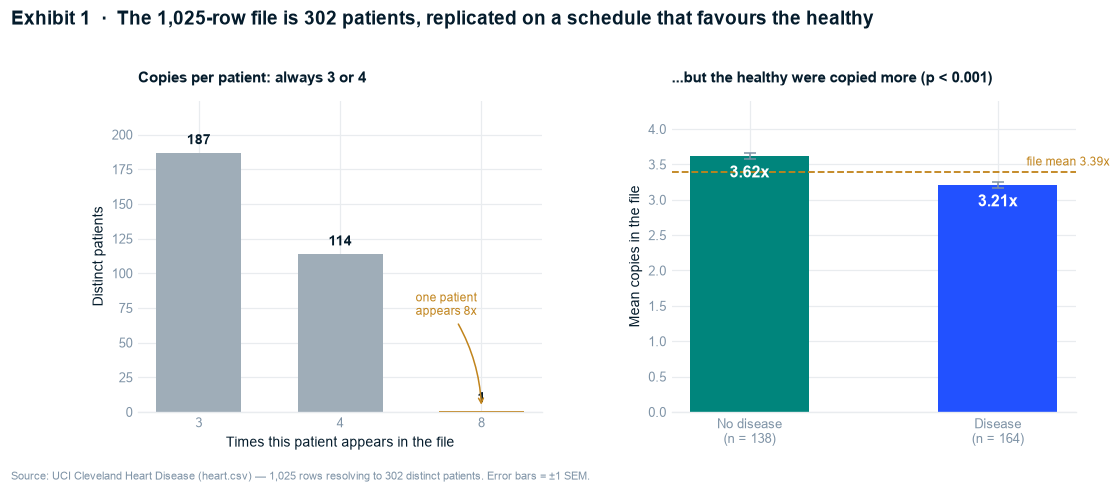

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
fig.subplots_adjust(wspace=0.32, top=0.80)

# Left: multiplicity distribution
ax = axes[0]
counts = dupe_profile["n_copies"].value_counts().sort_index()
bars = ax.bar([str(i) for i in counts.index], counts.values,
              color=[C_CONTEXT if i in (3, 4) else C_REF for i in counts.index], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 4, f"{v}", ha="center", va="bottom",
            fontsize=9, color=NAVY, fontweight="bold")
ax.set_title("Copies per patient: always 3 or 4", fontsize=10)
ax.set_xlabel("Times this patient appears in the file")
ax.set_ylabel("Distinct patients")
ax.set_ylim(0, counts.max() * 1.20)
ax.annotate("one patient\nappears 8x", xy=(2, 3), xytext=(1.75, 70),
            fontsize=8, color=AMBER, ha="center",
            arrowprops=dict(arrowstyle="->", color=AMBER, lw=1,
                            connectionstyle="arc3,rad=-0.15"))

# Right: mean copies by outcome
ax = axes[1]
means = dupe_profile.groupby("target")["n_copies"].mean()
sems = dupe_profile.groupby("target")["n_copies"].sem()
labels = ["No disease\n(n = 138)", "Disease\n(n = 164)"]
bars = ax.bar(labels, means.values, yerr=sems.values, capsize=4,
              color=[C_NODISEASE, C_DISEASE], width=0.48,
              error_kw=dict(ecolor=SLATE, lw=1))
for b, v in zip(bars, means.values):
    ax.text(b.get_x() + b.get_width() / 2, v - 0.3, f"{v:.2f}x", ha="center",
            fontsize=10.5, color="white", fontweight="bold")
ax.set_title("...but the healthy were copied more (p < 0.001)", fontsize=10)
ax.set_ylabel("Mean copies in the file")
ax.set_ylim(0, 4.4)
file_mean = len(df) / len(dupe_profile)
ax.axhline(file_mean, color=C_REF, lw=1.2, ls="--", zorder=1)
ax.text(1.45, file_mean + 0.09, f"file mean {file_mean:.2f}x",
        fontsize=8, color=AMBER, ha="right")

fig.suptitle("Exhibit 1  ·  The 1,025-row file is 302 patients, replicated on a schedule that favours the healthy",
             x=0.02, ha="left", fontsize=12.5, fontweight="bold", color=NAVY, y=1.00)
fig.text(0.02, -0.04, "Source: UCI Cleveland Heart Disease (heart.csv) — 1,025 rows resolving to 302 distinct "
                      "patients. Error bars = ±1 SEM.", fontsize=7.5, color=SLATE, ha="left")
save_exhibit(fig, "ex01_duplication")
plt.show()

> **So What:** the file's size is fiction. Treating 1,025 rows as 1,025 patients over-states the
> evidence base by 3.4× and silently re-weights the cohort toward healthy patients.
>
> **Implication:** deduplicate before anything else. Report the effective sample size (302) on
> the first page of the deliverable, not in an appendix.

In [6]:
# Deduplicate. n_copies and is_duplicate_row are AUDIT columns - never model inputs.
clean = dupe_profile.copy()
clean["is_duplicate_row"] = clean["n_copies"] > 1
clean = clean[FEATURES + ["target", "n_copies", "is_duplicate_row"]].reset_index(drop=True)

dupe_profile.to_parquet(PROC_DIR / "heart_raw_dupes.parquet", index=False)

print(f"rows before : {len(df):,}")
print(f"rows after  : {len(clean):,}   ({len(df) - len(clean):,} duplicate rows removed)")
print(f"label split : {clean['target'].value_counts().sort_index().to_dict()} "
      f"-> {clean['target'].mean():.1%} positive")

rows before : 1,025
rows after  : 302   (723 duplicate rows removed)
label split : {0: 138, 1: 164} -> 54.3% positive


## 2.2 Hidden missing data — `thal = 0` and `ca = 4`

Stage 1 flagged 7 rows with `thal = 0` and 18 with `ca = 4`. Those counts are inflated by the
duplication. At the **patient** level the true extent is far smaller — and worth measuring before
choosing a strategy, because the right handling for 25 rows is not the right handling for 6
patients.

In [7]:
PLACEHOLDERS = {"thal": 0, "ca": 4}

ph_rows = []
for col, bad in PLACEHOLDERS.items():
    ph_rows.append({
        "column": col,
        "illegal_code": bad,
        "rows_in_raw_file": int((df[col] == bad).sum()),
        "distinct_patients": int((clean[col] == bad).sum()),
        "pct_of_patients": f"{(clean[col] == bad).mean():.1%}",
    })
ph = pd.DataFrame(ph_rows)
display(ph)

affected = clean[(clean["thal"] == 0) | (clean["ca"] == 4)]
print(f"patients affected by at least one placeholder: {len(affected)} "
      f"({len(affected) / len(clean):.1%} of the cohort); overlap between the two: "
      f"{int(((clean['thal'] == 0) & (clean['ca'] == 4)).sum())}")
display(affected[["age", "sex", "cp", "trestbps", "chol", "thalach", "ca", "thal", "target"]])

,column,illegal_code,rows_in_raw_file,distinct_patients,pct_of_patients
0,thal,0,7,2,0.7%
1,ca,4,18,4,1.3%


patients affected by at least one placeholder: 6 (2.0% of the cohort); overlap between the two: 0


,age,sex,cp,trestbps,chol,thalach,ca,thal,target
9,38,1,2,138,175,173,4,2,1
41,43,1,0,132,247,143,4,3,0
110,52,1,0,128,204,156,0,0,0
115,52,1,2,138,223,169,4,2,1
121,53,0,2,128,216,115,0,0,1
193,58,1,1,125,220,144,4,3,1


**6 patients, ~2% of the cohort** — not 25 rows. The inflated counts were another artifact of the
duplication.

### Strategy, and why the stakes are low by construction

These are **MNAR-suspected**: a test result is missing because the test was not completed or was
unreadable, which may itself relate to the patient's condition. So:

- **Recode to `NaN`.** Never impute a mode into a placeholder — that manufactures a thallium
  result and a vessel count that were never measured, in the two strongest predictors.
- **Carry as an explicit `unknown` category** for the model, rather than dropping 6 patients out
  of 302. "Test not completed" is legitimate information, not noise.
- **Sensitivity check in Stage 5b:** re-fit with those 6 patients dropped, and confirm the
  headline conclusion does not move.

The decision is genuinely low-stakes here, and the reason is structural: `ca` and `thal` are both
**quarantined into Scope 2** (see §2.4), because both are produced by the same catheterisation
and perfusion workup that *defines* the target. The primary Scope 1 model never sees either
column, so this imputation choice cannot touch the headline result at all.

In [8]:
before = {c: int((clean[c] == v).sum()) for c, v in PLACEHOLDERS.items()}
for col, bad in PLACEHOLDERS.items():
    clean[col] = clean[col].replace(bad, np.nan)

recode_check = pd.DataFrame({
    "column": list(PLACEHOLDERS),
    "recoded_to_nan": [before[c] for c in PLACEHOLDERS],
    "nulls_now": [int(clean[c].isna().sum()) for c in PLACEHOLDERS],
    "remaining_domain": ["{" + ",".join(str(int(v)) for v in sorted(clean[c].dropna().unique())) + "}"
                         for c in PLACEHOLDERS],
})
display(recode_check)
print(f"total nulls in the cleaned frame: {int(clean.isna().sum().sum())} "
      f"(all deliberate, all in ca/thal)")

,column,recoded_to_nan,nulls_now,remaining_domain
0,thal,2,2,"{1,2,3}"
1,ca,4,4,"{0,1,2,3}"


total nulls in the cleaned frame: 6 (all deliberate, all in ca/thal)


## 2.3 Types and the nominal-encoding contract

The most consequential typing decision in this dataset. `DOCS/heart_dataset_analysis.md` §5 warns
that the integer codes in `cp`, `restecg`, and `thal` are **labels, not magnitudes** — computing a
"mean chest-pain type" or fitting a single linear coefficient across them would invent a severity
scale that does not exist.

This contract is fixed here and enforced through the `ColumnTransformer` in Stage 4.

In [9]:
CONTRACT = pd.DataFrame([
    ("age",      "numeric",  "float64", "Years. Continuous."),
    ("sex",      "binary",   "int8",    "0 = female, 1 = male. PROTECTED ATTRIBUTE."),
    ("cp",       "NOMINAL",  "category", "Chest-pain type. One-hot ONLY - the codes are not a severity scale."),
    ("trestbps", "numeric",  "float64", "Resting systolic BP, mm Hg."),
    ("chol",     "numeric",  "float64", "Serum cholesterol, mg/dl. Right-skewed."),
    ("fbs",      "binary",   "int8",    "Fasting blood sugar > 120 mg/dl."),
    ("restecg",  "NOMINAL",  "category", "Resting ECG result. One-hot - 'ST-T abnormality' and 'LVH' are not ordered."),
    ("thalach",  "numeric",  "float64", "Max heart rate achieved, bpm. Confounded with age -> see hr_reserve."),
    ("exang",    "binary",   "int8",    "Exercise-induced angina."),
    ("oldpeak",  "numeric",  "float64", "ST depression vs rest, mm. Right-skewed, zero-inflated."),
    ("slope",    "ORDINAL",  "int8",    "ST slope up/flat/down - genuinely ordered. Deliberate exception."),
    ("ca",       "ORDINAL",  "float64", "Vessel count 0-3 - genuinely ordered. Nullable (placeholders). SCOPE 2 ONLY."),
    ("thal",     "NOMINAL",  "category", "Thallium result. Nullable (placeholders). SCOPE 2 ONLY."),
    ("target",   "label",    "int8",    "1 = angiographic disease present."),
], columns=["column", "treatment", "dtype", "note"])
CONTRACT

,column,treatment,dtype,note
0,age,numeric,float64,Years. Continuous.
1,sex,binary,int8,"0 = female, 1 = male. PROTECTED ATTRIBUTE."
2,cp,NOMINAL,category,Chest-pain type. One-hot ONLY - the codes are ...
3,trestbps,numeric,float64,"Resting systolic BP, mm Hg."
4,chol,numeric,float64,"Serum cholesterol, mg/dl. Right-skewed."
5,fbs,binary,int8,Fasting blood sugar > 120 mg/dl.
6,restecg,NOMINAL,category,Resting ECG result. One-hot - 'ST-T abnormalit...
7,thalach,numeric,float64,"Max heart rate achieved, bpm. Confounded with ..."
8,exang,binary,int8,Exercise-induced angina.
9,oldpeak,numeric,float64,"ST depression vs rest, mm. Right-skewed, zero-..."


In [10]:
for c in ["age", "trestbps", "chol", "thalach", "oldpeak"]:
    clean[c] = clean[c].astype("float64")
for c in ["sex", "fbs", "exang", "slope", "target"]:
    clean[c] = clean[c].astype("int8")
clean["ca"] = clean["ca"].astype("float64")     # nullable after recoding

print(clean.dtypes.to_string())

age                 float64
sex                    int8
cp                    int64
trestbps            float64
chol                float64
fbs                    int8
restecg               int64
thalach             float64
exang                  int8
oldpeak             float64
slope                  int8
ca                  float64
thal                float64
target                 int8
n_copies              int64
is_duplicate_row       bool


## 2.4 Feature scope — quarantining the angiography-derived columns

This is the analytical spine of the project, so it is fixed in cleaning rather than improvised at
model time.

The target is **angiographic disease** — >50% narrowing found on cardiac catheterisation. Two
features come from that same workup:

- **`ca`** — major vessels coloured by fluoroscopy. Measured *during* catheterisation.
- **`thal`** — thallium perfusion scan. Part of the same diagnostic cascade.

Using them to "predict" the catheterisation result is close to circular. It is not a coding bug —
it produces genuinely high accuracy — but it answers a question nobody needs answered, because by
the time you have `ca` you already have the diagnosis.

**Resolution: two scopes, run through an identical pipeline, reported side by side.**

In [11]:
SCOPE1 = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
          "thalach", "exang", "oldpeak", "slope"]          # pre-catheterisation
SCOPE2 = SCOPE1 + ["ca", "thal"]                            # + angiography-derived

scopes = pd.DataFrame([
    {"scope": "Scope 1 - Pre-test", "n_features": len(SCOPE1),
     "question": "Given history, resting workup and a stress test, how likely is disease?",
     "role": "PRIMARY - decision-relevant; carries the recommendation"},
    {"scope": "Scope 2 - Post-cath", "n_features": len(SCOPE2),
     "question": "How well do classes separate when label-adjacent measurements are allowed in?",
     "role": "COMPARATOR - the configuration published benchmarks silently use"},
])
display(scopes)
print(f"Scope 1 ({len(SCOPE1)}): {', '.join(SCOPE1)}")
print(f"Scope 2 ({len(SCOPE2)}): {', '.join(SCOPE2)}")

,scope,n_features,question,role
0,Scope 1 - Pre-test,11,"Given history, resting workup and a stress tes...",PRIMARY - decision-relevant; carries the recom...
1,Scope 2 - Post-cath,13,How well do classes separate when label-adjace...,COMPARATOR - the configuration published bench...


Scope 1 (11): age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope
Scope 2 (13): age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal


## 2.5 Outliers — inspected, retained, documented

`DOCS/STRUCTURE.md`: *never remove outliers without a documented reason.* Here the documented
reason runs the other way — the extremes are clinically real and are kept.

In [12]:
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
rows = []
for c in NUMERIC:
    s = clean[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({
        "column": c, "min": s.min(), "max": s.max(),
        "skew": round(s.skew(), 2),
        "iqr_outliers": int(((s < lo) | (s > hi)).sum()),
        "verdict": "RETAIN - clinically plausible",
    })
outliers = pd.DataFrame(rows)
display(outliers)

print(f"chol == 0 (the Hungarian/Swiss placeholder pattern): {int((clean['chol'] == 0).sum())} "
      "-> absent, corroborating that this file is Cleveland-only")
print(f"oldpeak == 0 (a genuine flat result, not missing):    {int((clean['oldpeak'] == 0).sum())} "
      f"({(clean['oldpeak'] == 0).mean():.1%} of patients)")

,column,min,max,skew,iqr_outliers,verdict
0,age,29.0,77.0,-0.20,0,RETAIN - clinically plausible
1,trestbps,94.0,200.0,0.72,9,RETAIN - clinically plausible
2,chol,126.0,564.0,1.15,5,RETAIN - clinically plausible
3,thalach,71.0,202.0,-0.53,1,RETAIN - clinically plausible
4,oldpeak,0.0,6.2,1.27,5,RETAIN - clinically plausible


chol == 0 (the Hungarian/Swiss placeholder pattern): 0 -> absent, corroborating that this file is Cleveland-only
oldpeak == 0 (a genuine flat result, not missing):    98 (32.5% of patients)


**Retained, with reasons:**

- `chol` max **564 mg/dl** and `trestbps` max **200 mm Hg** are extreme but real — familial
  hypercholesterolaemia and severe hypertension exist. Deleting them would remove the highest-risk
  patients from a cardiac-risk analysis, which is the opposite of defensible.
- `oldpeak` is **zero-inflated (32% of patients)**. A zero is a genuine flat ST response, not a
  missing value. This is a *modelling* consideration — it favours tree-based splits over a linear
  term — and it is recorded here rather than "fixed".
- **`chol == 0` does not occur.** The Hungarian and Swiss subsets of the UCI collection are full
  of zero-cholesterol placeholders; their absence is independent corroboration that this file is
  the Cleveland cohort only, matching the data notes.

Standardisation at model time handles the scale disparity. Nothing is deleted.

## 2.6 Feature engineering — deliberately deferred

`DOCS/heart_dataset_analysis.md` §7 proposes derived features (`hr_reserve`, `chol_flag`,
`bp_flag`, `st_severity`, `age_group`, `risk_factor_count`, `cp_asymptomatic`). **None are created
here.**

Threshold and binning features are fit-dependent: their cut points must be learned inside
cross-validation folds, not on the full dataset. Creating them now would leak the validation folds
into the transform. They are therefore built inside the `Pipeline` in Stage 4 — and each is
**ablation-tested** rather than assumed useful, because at n = 302 a derived feature is as likely
to add variance as signal.

The two columns created here — `n_copies` and `is_duplicate_row` — are **audit trail only** and
are excluded from every feature matrix.

In [13]:
CLEANING_LOG = pd.DataFrame([
    {"step": 1, "action": "Deduplicate to distinct patients",
     "rows_affected": len(df) - len(clean), "cols_affected": 0,
     "why": "723 of 1,025 rows (70.5%) were exact copies; effective n is 302. Copying was "
            "non-uniform and correlated with target (p < 0.001), distorting both splits and weights."},
    {"step": 2, "action": "Add audit columns n_copies, is_duplicate_row",
     "rows_affected": len(clean), "cols_affected": 2,
     "why": "Preserve the duplication evidence for the Stage 5b leakage experiment. Never model inputs."},
    {"step": 3, "action": "Recode thal = 0 -> NaN",
     "rows_affected": before["thal"], "cols_affected": 1,
     "why": "Outside the documented domain {1,2,3}; a UCI '?' placeholder coerced to 0. MNAR-suspected."},
    {"step": 4, "action": "Recode ca = 4 -> NaN",
     "rows_affected": before["ca"], "cols_affected": 1,
     "why": "Outside the documented domain {0,1,2,3}; a UCI '?' placeholder coerced to 4. MNAR-suspected."},
    {"step": 5, "action": "Enforce dtype + nominal-encoding contract",
     "rows_affected": 0, "cols_affected": len(CONTRACT),
     "why": "cp/restecg/thal are nominal labels, not severity scales; slope/ca are genuinely ordered."},
    {"step": 6, "action": "Retain all outliers",
     "rows_affected": 0, "cols_affected": 0,
     "why": "chol 564 / trestbps 200 are clinically plausible extremes; removing them would drop "
            "the highest-risk patients. Handled by standardisation, not deletion."},
    {"step": 7, "action": "Defer all derived features to the Stage 4 Pipeline",
     "rows_affected": 0, "cols_affected": 0,
     "why": "Threshold/binning features are fit-dependent; building them here would leak CV folds."},
])
CLEANING_LOG.to_csv(PROC_DIR / "_cleaning_log.csv", index=False)
CLEANING_LOG

,step,action,rows_affected,cols_affected,why
0,1,Deduplicate to distinct patients,723,0,"723 of 1,025 rows (70.5%) were exact copies; e..."
1,2,"Add audit columns n_copies, is_duplicate_row",302,2,Preserve the duplication evidence for the Stag...
2,3,Recode thal = 0 -> NaN,2,1,"Outside the documented domain {1,2,3}; a UCI '..."
3,4,Recode ca = 4 -> NaN,4,1,"Outside the documented domain {0,1,2,3}; a UCI..."
4,5,Enforce dtype + nominal-encoding contract,0,14,"cp/restecg/thal are nominal labels, not severi..."
5,6,Retain all outliers,0,0,chol 564 / trestbps 200 are clinically plausib...
6,7,Defer all derived features to the Stage 4 Pipe...,0,0,Threshold/binning features are fit-dependent; ...


In [14]:
clean.to_parquet(PROC_DIR / "heart_clean.parquet", index=False)

print(f"wrote data/processed/heart_clean.parquet   {clean.shape[0]} patients x {clean.shape[1]} columns")
print(f"wrote data/processed/heart_raw_dupes.parquet  (302 patients + n_copies, for the leakage experiment)")
print(f"wrote data/processed/_cleaning_log.csv     {len(CLEANING_LOG)} logged actions\n")
display(clean.head())
print(f"\nnulls by column (deliberate only):\n{clean.isna().sum()[lambda s: s > 0].to_string()}")

wrote data/processed/heart_clean.parquet   302 patients x 16 columns
wrote data/processed/heart_raw_dupes.parquet  (302 patients + n_copies, for the leakage experiment)
wrote data/processed/_cleaning_log.csv     7 logged actions



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,n_copies,is_duplicate_row
0,29.0,1,1,130.0,204.0,0,0,202.0,0,0.0,2,0.0,2.0,1,4,True
1,34.0,0,1,118.0,210.0,0,1,192.0,0,0.7,2,0.0,2.0,1,3,True
2,34.0,1,3,118.0,182.0,0,0,174.0,0,0.0,2,0.0,2.0,1,3,True
3,35.0,0,0,138.0,183.0,0,1,182.0,0,1.4,2,0.0,2.0,1,4,True
4,35.0,1,0,120.0,198.0,0,1,130.0,1,1.6,1,0.0,3.0,0,4,True



nulls by column (deliberate only):
ca      4
thal    2


---

## Stage 2 — Gate Checklist

- [x] **Missing value strategy documented per column** — `thal = 0` (2 patients) and `ca = 4`
      (4 patients) recoded to `NaN`, MNAR-suspected, carried as explicit `unknown` rather than
      imputed; sensitivity check scheduled in Stage 5b. No other column has missingness.
- [x] **Duplicates assessed and handled with justification** — not merely dropped:
      characterised as non-uniform (3–4 copies each), outcome-correlated (p < 0.001), and
      feature-correlated (8 of 13 features), which upgrades the finding from "leakage" to
      "leakage **plus** distorted case weighting".
- [x] **All columns have correct dtypes** — nominal-encoding contract fixed in §2.3 and enforced
      downstream by `ColumnTransformer`.
- [x] **Business-rule validations pass** — the two Stage 1 domain violations are now resolved;
      all continuous ranges were already plausible.
- [x] **Cleaning log exists** — `data/processed/_cleaning_log.csv`, 7 actions with rows affected
      and rationale.
- [x] **Cleaned data saved to `data/processed/`** — `heart_clean.parquet` (302 × 16).

### Carried into Stage 3

| Decision | Consequence |
|---|---|
| n = **302 patients**, 164 disease / 138 no-disease (54.3% positive) | Every statistic and every model uses this. Stratify all splits. |
| `cp`, `restecg`, `thal` are **nominal** | No means, no correlations, no single linear coefficient on these codes. |
| `ca`, `thal` **quarantined to Scope 2** | Scope 1 (11 pre-test features) is primary and carries the recommendation. |
| `oldpeak` is 32% zero-inflated | Favours tree splits; noted for model selection. |

**Next:** `03_eda.ipynb` — hypothesis-driven exploration, one section per issue-tree branch.